# 1. Evaluating a New Human Motion Prediction Model

This notebook demonstrates the complete evaluation pipeline using `HMPEvaluator` (powered by `hmp_utils`), covering:
1. Initializing the normalized evaluator (`1 m` left femur),
2. Computing `MPJPE`, `JAD`, `PSDS`, and `HMPE_t` on angle-axis predictions (plus converting 3D joint positions via Inverse Kinematics for position-based models),
3. Running the full evaluation protocol (exporting all 19 CSV logs) on AMASS or Human3.6M,
4. Comparing your model directly against the paper's benchmark models using `extra_models`.

In [1]:
import numpy as np
from hmp_evaluation import (
    HMPEvaluator,
    compute_zero_velocity_baseline,
    compute_hmpe_score,
    get_reference_psds,
)

## 1.1 Initialize the Evaluator

`HMPEvaluator` configures `ForwardKinematics` (`set_body_model_type` followed by `normalize_joints`) so that the reference left femur (`JOINT_TO_NORMALIZE`) has a length of exactly $1\text{ m}$.

In [2]:
# Choose dataset ("amass" or "h36m") and framerate (25 or 60)
evaluator = HMPEvaluator(dataset="amass", framerate=25, normalize_skeleton=True)

## 1.2 Compute MPJPE, JAD, PSDS, and HMPE on Predictions

Predictions and ground-truth targets are provided in **angle-axis** representation with shape `(batch_size, seq_len, num_joints, 3)`.
- **Accuracy (`MPJPE` in $\text{mm}$, `JAD` in $\text{rad}$)** is evaluated frame-by-frame against future ground truth over the first $1\text{ s}$ (`target_seq_len = framerate`, i.e., 25 frames at 25 fps or 60 frames at 60 fps).
- **Realism (`PSDS`)** requires **no ground-truth future poses**: it compares the normalized Power Spectral Density (PSD) of the **predicted** rollout over sliding $1\text{ s}$ windows directly against the pre-computed dataset training-set PSD bundled in `hmp_utils` (for long-horizon realism curves up to $30\text{ s}$ as in Figs. 5, 7, and 10, pass a rollout of `30 * framerate` frames).
- **`HMPE_t` (Human Motion Prediction Error, Eq. 9)** aggregates `MPJPE_t`, `JAD_t`, and `PSDS` (at $1000\text{ ms}$) into a single score in $[0, 100]$ (lower is better), computed as the normalized triangle area of the 3-axis radar chart. Each accuracy axis is normalized by the Zero-Velocity baseline (`ZeroVel`) and clipped to $[0, 1]$, while the `PSDS` axis is normalized by $10 \times \text{PSDS}(\text{Train}, \text{Test})$ (one order of magnitude above the natural train-test spectral shift, as defined in the paper). A model matching `ZeroVel` on all axes therefore scores `100.00`, while an ideal predictor scores `0.00`.

In [ ]:
# Simple synthetic example (batch=8, 30 s = 750 frames at 25 fps so PSDS covers the full 30 s horizon)
rng = np.random.RandomState(42)
seq_len = 30 * evaluator.framerate  # 750 frames at 25 fps
last_input_pose = rng.normal(0.0, 0.12, size=(8, 24, 3))  # Last observed input pose at t = 0 ms
gt_aa = rng.normal(0.0, 0.12, size=(8, seq_len, 24, 3))  # Ground-truth future starting at t = +40 ms
pred_aa = gt_aa + rng.normal(0.0, 0.085, size=(8, seq_len, 24, 3))  # Synthetic predictions (~150 mm MPJPE / ~0.14 rad JAD)
zerovel_aa = compute_zero_velocity_baseline(last_input_pose, target_seq_len=seq_len)

# Direct per-frame MPJPE [mm], JAD [rad] over the first 1 s, and sliding-window PSDS on predictions
one_sec = evaluator.framerate
mpjpe_mm = evaluator.compute_mpjpe(pred_aa[:, :one_sec], gt_aa[:, :one_sec])
jad_rad = evaluator.compute_jad(pred_aa[:, :one_sec], gt_aa[:, :one_sec])
psds_curve = evaluator.compute_psds(pred_aa)

zv_mpjpe_mm = evaluator.compute_mpjpe(zerovel_aa[:, :one_sec], gt_aa[:, :one_sec])
zv_jad_rad = evaluator.compute_jad(zerovel_aa[:, :one_sec], gt_aa[:, :one_sec])
psds_train_test = get_reference_psds("amass_25fps", "train", "test")

# 0-indexed frame positions corresponding to 400 ms and 1000 ms (at 25 fps: frame 0 -> 40 ms, frame 9 -> 400 ms, frame 24 -> 1000 ms)
ms_per_frame = 1000.0 / evaluator.framerate
idx_400 = int(round(400.0 / ms_per_frame)) - 1
idx_1000 = int(round(1000.0 / ms_per_frame)) - 1

hmpe_400, _ = compute_hmpe_score(
    mpjpe_t=mpjpe_mm[idx_400],
    jad_t=jad_rad[idx_400],
    psds_1000=psds_curve[0],
    zero_vel_mpjpe_t=zv_mpjpe_mm[idx_400],
    zero_vel_jad_t=zv_jad_rad[idx_400],
    psds_train_test=psds_train_test,
)
hmpe_1000, _ = compute_hmpe_score(
    mpjpe_t=mpjpe_mm[idx_1000],
    jad_t=jad_rad[idx_1000],
    psds_1000=psds_curve[0],
    zero_vel_mpjpe_t=zv_mpjpe_mm[idx_1000],
    zero_vel_jad_t=zv_jad_rad[idx_1000],
    psds_train_test=psds_train_test,
)

print(f"MPJPE @ 400 ms:  {mpjpe_mm[idx_400]:.1f} mm | @ 1000 ms: {mpjpe_mm[idx_1000]:.1f} mm")
print(f"JAD   @ 400 ms:  {jad_rad[idx_400]:.3f} rad | @ 1000 ms: {jad_rad[idx_1000]:.3f} rad")
print(f"PSDS  @ 1000 ms: {psds_curve[0]:.4f} (Train-Test ref: {psds_train_test:.4f})")
print(f"HMPE_400: {hmpe_400:.2f} | HMPE_1000: {hmpe_1000:.2f}")

MPJPE @ 400 ms:  158.4 mm | @ 1000 ms: 146.8 mm
JAD   @ 400 ms:  0.129 rad | @ 1000 ms: 0.144 rad
PSDS  @ 1000 ms: 4.7362 (Train-Test ref: 0.0221)
HMPE_400: 44.87 | HMPE_1000: 44.10


### Optional: Models Predicting 3D Joint Positions

If your model predicts **3D Cartesian joint coordinates in meters** instead of angle-axis rotations, convert your model's predicted positions to full-skeleton angle-axis rotations via `evaluator.positions_to_angle_axis(...)` before calling `evaluate_action()`.

SMPL has 24 joints (`0..23`); if your architecture predicts only a subset of active body joints (for example, `np.arange(4, 22)` selects the 18 active body joints excluding pelvis/hips `0-3` and hand tips `22-23`), pass those indices via `joint_indices` so Inverse Kinematics reconstructs the full 24-joint tensor.

In [4]:
from hmp_utils import ForwardKinematics, SmplConstants

# Subset of 18 SMPL joints (indices 4..21: legs, spine, arms, excluding root/hips 0-3 and hands 22-23)
joint_used = np.arange(4, 22)

# Demo only: use FK on `pred_aa` solely to synthesize dummy 3D joint positions mimicking
# a position-based network's output. In real usage, pass your model's predicted 3D positions
# (in meters) directly to `positions_to_angle_axis()`; you do NOT run FK before IK.
fk_raw = ForwardKinematics(SmplConstants.OFFSETS, SmplConstants.PARENTS)
fk_raw.set_body_model_type(SmplConstants.BODY_MODEL_TYPE)
pred_pos_meters = fk_raw.compute_fk(pred_aa[:, :one_sec], apply_root_rotation=False)[:, :, joint_used, :]

pred_aa_from_ik = evaluator.positions_to_angle_axis(
    joint_positions=pred_pos_meters,
    joint_indices=joint_used,
    ignore_root_joint=True,
)
print(f"3D positions {pred_pos_meters.shape} -> IK angle-axis {pred_aa_from_ik.shape}")

3D positions (8, 25, 18, 3) -> IK angle-axis (8, 25, 24, 3)


## 1.3 Run the Full Protocol and Export CSV Logs

Calling `evaluate_action()` and `save_results()` exports a directory of 19 CSV files directly compatible with all table and plotting utilities.

- **AMASS**: call `evaluate_action(..., action="amass", target_seq_len=evaluator.framerate)` once on the full test set. Note that if your rollout for `PSDS` is longer than the available $1\text{ s}$ ground truth (e.g., $30\text{ s}$), pad `targets` to match `predictions.shape` (accuracy metrics only read the first `target_seq_len` frames, while `PSDS` uses only `predictions`).
- **Human3.6M**: loop over all 15 actions (`for action in H36M_ACTIONS: evaluator.evaluate_action(preds[action], gts[action], action=action, target_seq_len=25)`), then call `evaluator.save_results(...)`, which automatically computes and appends the `mean` row across all actions.

In [5]:
evaluator.reset()
evaluator.evaluate_action(predictions=pred_aa, targets=gt_aa, action="amass", target_seq_len=one_sec)
out_dir = evaluator.save_results("./my_custom_model_eval")

Saved Default Error to my_custom_model_eval/Default_Error.csv
Saved Euler Error XYZ to my_custom_model_eval/Euler_Error_XYZ.csv
Saved Euler Error ZXY to my_custom_model_eval/Euler_Error_ZXY.csv
Saved Joint Angle Diff Local to my_custom_model_eval/Joint_Angle_Diff_Local.csv
Saved Joint Angle Diff Global to my_custom_model_eval/Joint_Angle_Diff_Global.csv
Saved Positional Error to my_custom_model_eval/Positional_Error.csv
Saved Wasserstein Distance to my_custom_model_eval/Wasserstein_Distance.csv
Saved Cumulative Default Error to my_custom_model_eval/Cumulative_Default_Error.csv
Saved Cumulative Euler Error XYZ to my_custom_model_eval/Cumulative_Euler_Error_XYZ.csv
Saved Cumulative Euler Error ZXY to my_custom_model_eval/Cumulative_Euler_Error_ZXY.csv
Saved Cumulative Joint Angle Diff Local to my_custom_model_eval/Cumulative_Joint_Angle_Diff_Local.csv
Saved Cumulative Joint Angle Diff Global to my_custom_model_eval/Cumulative_Joint_Angle_Diff_Global.csv
Saved Cumulative Positional Error 

## 1.4 Compare Against the Paper's Benchmark Models (`extra_models`)

Pass `extra_models={"MyModel": out_dir}` to any table or plotting function to append your evaluated model alongside the paper's baselines (`ZeroVel`, `HRI`, `DMGNN`, `PVRED`, `AuxFormer`) without modifying `benchmark_results/`.

=== AMASS (25 fps) MPJPE [mm] ===
| Model     | 40 ms | 120 ms | 200 ms | 400 ms | 600 ms | 800 ms | 1000 ms |
| --------- | ----- | ------ | ------ | ------ | ------ | ------ | ------- |
| ZeroVel   | 28.1  | 78.7   | 119.4  | 187.3  | 219.0  | 220.8  | 215.4   |
| HRI       | 9.7   | 30.3   | 48.7   | 84.5   | 110.7  | 127.2  | 139.8   |
| DMGNN     | 21.6  | 49.7   | 76.0   | 120.7  | 145.3  | 160.5  | 172.8   |
| PVRED     | 14.7  | 40.8   | 62.5   | 101.3  | 127.4  | 143.8  | 154.2   |
| AuxFormer | 9.3   | 29.4   | 48.8   | 88.2   | 114.8  | 131.3  | 145.2   |
| MyModel   | 156.3 | 155.9  | 143.7  | 158.4  | 171.5  | 136.8  | 146.8   |

=== AMASS (25 fps) HMPE ===
| Model     | HMPE_400ms | HMPE_1000ms | Increase [pp] |
| --------- | ---------- | ----------- | ------------- |
| ZeroVel   | 100.00     | 100.00      | 0.00          |
| HRI       | 26.19      | 38.76       | 12.57         |
| DMGNN     | 49.57      | 61.87       | 12.30         |
| PVRED     | 25.18      | 35.04    

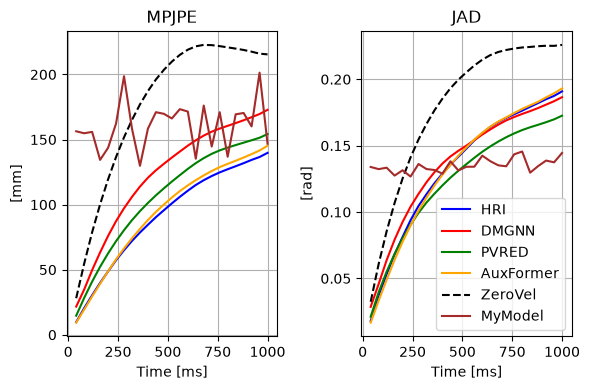

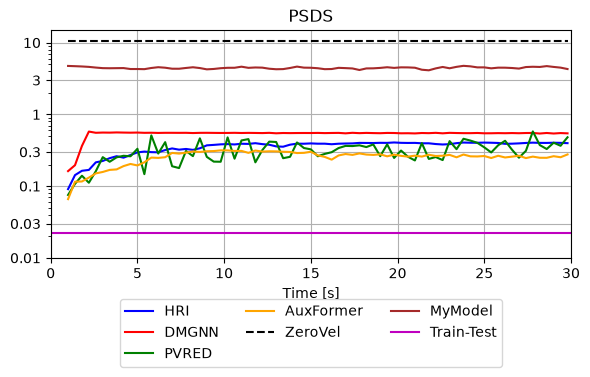

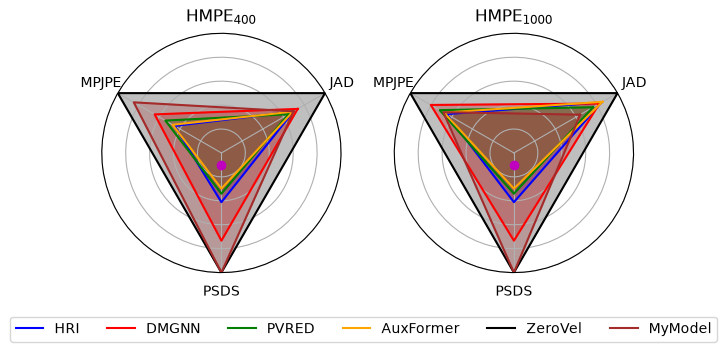

In [6]:
from hmp_evaluation import (
    format_metric_table,
    format_hmpe_table,
    plot_mpjpe_and_jad,
    plot_psds,
    plot_hmpe_radar,
)

custom = {"MyModel": out_dir}

print("=== AMASS (25 fps) MPJPE [mm] ===")
print(format_metric_table("amass_25fps", "MPJPE", extra_models=custom))
print("\n=== AMASS (25 fps) HMPE ===")
print(format_hmpe_table("amass_25fps", extra_models=custom))

plot_mpjpe_and_jad("amass_25fps", extra_models=custom)
plot_psds("amass_25fps", extra_models=custom)
plot_hmpe_radar("amass_25fps", extra_models=custom)